# California Housing — ML Capstone Project

This notebook implements the required Machine Learning Capstone pipeline using the provided `housing.csv` dataset: exploratory data analysis, preprocessing, regression, classification, and K-Means clustering.

**Important:** This notebook is self-contained. You can upload it to Google Colab and then upload `housing.csv` when prompted. It does not require the project ZIP or `run_project.py`.


## 1. Install and import libraries
Run this cell first. The required libraries are common in Google Colab; the install command is included for reproducibility.

In [1]:
%pip -q install pandas numpy scikit-learn matplotlib seaborn

import io, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import (mean_squared_error, r2_score, accuracy_score,
                             confusion_matrix, classification_report,
                             precision_score, recall_score, silhouette_score)
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
OUTPUT_DIR = Path('results')
OUTPUT_DIR.mkdir(exist_ok=True)
print('Libraries loaded. Results will be saved to:', OUTPUT_DIR.resolve())

Libraries loaded. Results will be saved to: /content/results


## 2. Load the dataset
Upload the `housing.csv` file that was provided for the project. If you are running locally, place it in the same folder as the notebook.

In [3]:
import pandas as pd

# Load the dataset
df = pd.read_csv('/content/housing.csv')

# Display the first 5 rows
df.head()
# Number of rows and columns
print("Dataset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and non-null values
print("\nDataset information:")
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Statistical summary
df.describe()

Dataset shape: (20640, 10)

Columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing values:
longitud

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


## 3. Exploratory Data Analysis (EDA)
Review descriptive statistics, target distribution, correlations, and missing values.

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
longitude,20640.0,NaN,NaN,NaN,-119.569704,2.003532,-124.35,-121.8,-118.49,-118.01,-114.31
latitude,20640.0,NaN,NaN,NaN,35.631861,2.135952,32.54,33.93,34.26,37.71,41.95
housing_median_age,20640.0,NaN,NaN,NaN,28.639486,12.585558,1.0,18.0,29.0,37.0,52.0
total_rooms,20640.0,NaN,NaN,NaN,2635.763081,2181.615252,2.0,1447.75,2127.0,3148.0,39320.0
total_bedrooms,20433.0,NaN,NaN,NaN,537.870553,421.38507,1.0,296.0,435.0,647.0,6445.0
population,20640.0,NaN,NaN,NaN,1425.476744,1132.462122,3.0,787.0,1166.0,1725.0,35682.0
households,20640.0,NaN,NaN,NaN,499.53968,382.329753,1.0,280.0,409.0,605.0,6082.0
median_income,20640.0,NaN,NaN,NaN,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,NaN,NaN,NaN,206855.816909,115395.615874,14999.0,119600.0,179700.0,264725.0,500001.0
ocean_proximity,20640,5,<1H OCEAN,9136,NaN,NaN,NaN,NaN,NaN,NaN,NaN


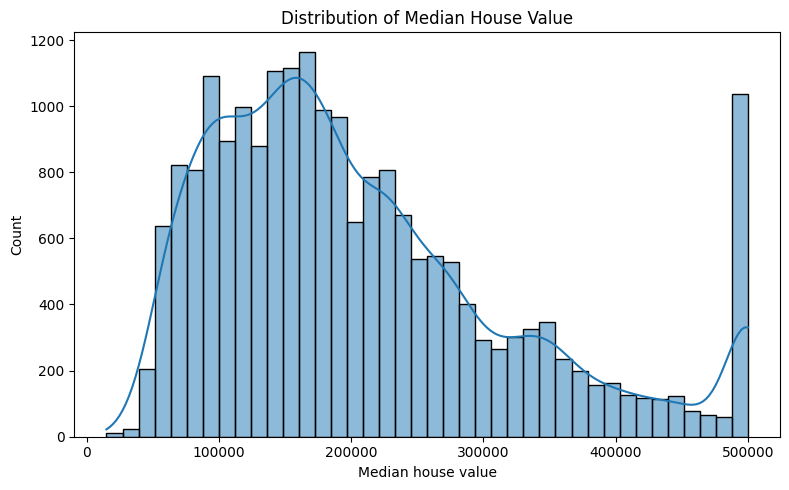

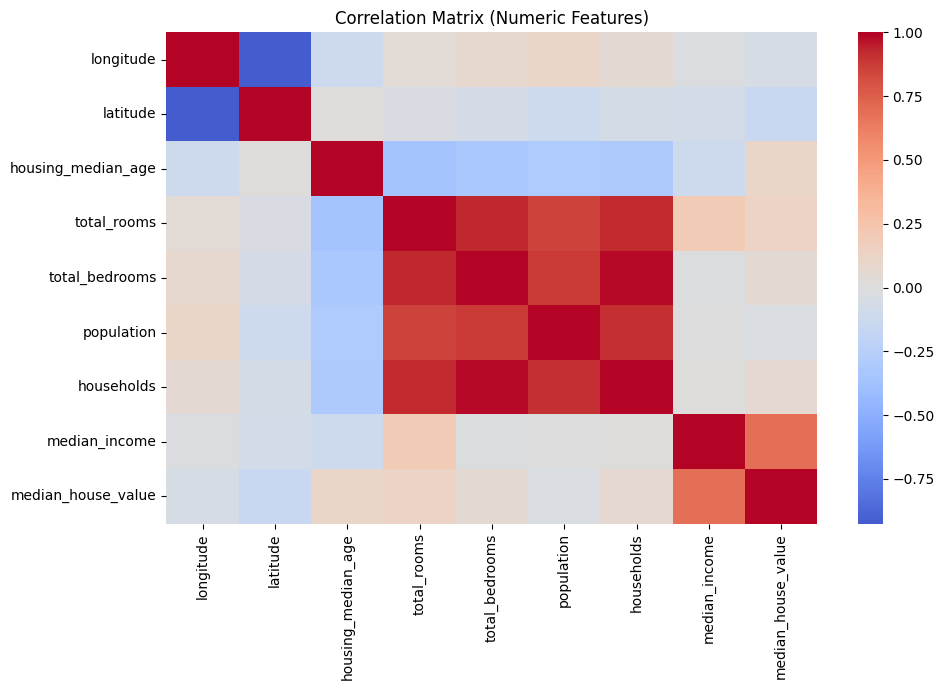

Rows with any missing value: 207


In [4]:
display(df.describe(include='all').T)
missing = df.isna().sum().rename('missing_count').to_frame()
missing.to_csv(OUTPUT_DIR / 'missing_values.csv')

if 'median_house_value' not in df.columns:
    raise ValueError("Expected target column 'median_house_value' was not found. Check that you uploaded the California Housing CSV.")

plt.figure(figsize=(8, 5))
sns.histplot(df['median_house_value'].dropna(), bins=40, kde=True)
plt.title('Distribution of Median House Value')
plt.xlabel('Median house value')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'target_distribution.png', dpi=150)
plt.show()

numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(10, 7))
sns.heatmap(numeric_df.corr(), cmap='coolwarm', center=0, annot=False)
plt.title('Correlation Matrix (Numeric Features)')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'correlation_matrix.png', dpi=150)
plt.show()
print('Rows with any missing value:', int(df.isna().any(axis=1).sum()))

## 4. Preprocessing
The continuous target is `median_house_value`. Numeric missing values are imputed with the median; categorical missing values use the most frequent category. One-hot encoding handles `ocean_proximity`. Preprocessing is fitted inside each training pipeline to prevent test-data leakage.

In [5]:
target = 'median_house_value'
X = df.drop(columns=[target]).copy()
y = df[target].copy()

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)
print('Training rows:', len(X_train), '| Test rows:', len(X_test))
print('Numeric features:', numeric_features)
print('Categorical features:', categorical_features)

Training rows: 16512 | Test rows: 4128
Numeric features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']


## 5. Regression — Linear Regression
Predict the continuous `median_house_value` target. Report MSE, RMSE, and R².

{
  "MSE": 4908290571.346432,
  "RMSE": 70059.19333925014,
  "R2": 0.6254382675296266
}


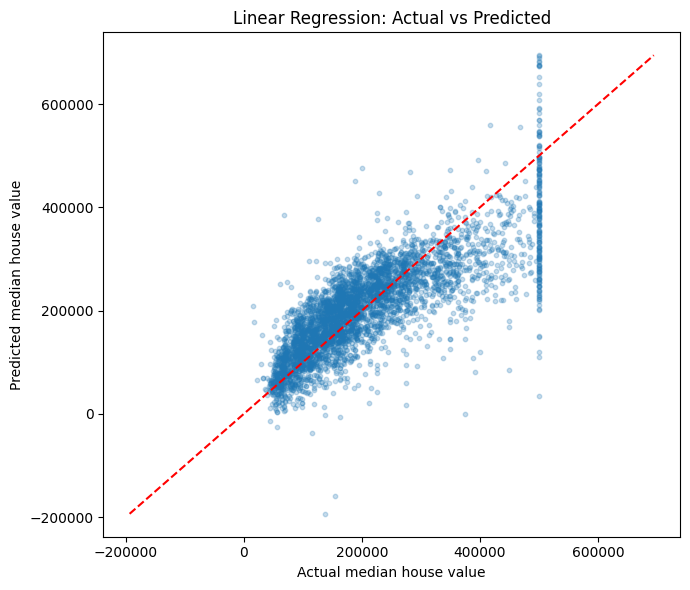

In [6]:
regression_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LinearRegression())
])
regression_model.fit(X_train, y_train)
y_pred = regression_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = float(np.sqrt(mse))
r2 = r2_score(y_test, y_pred)
regression_metrics = {'MSE': float(mse), 'RMSE': rmse, 'R2': float(r2)}
print(json.dumps(regression_metrics, indent=2))

plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.25, s=10)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, 'r--')
plt.xlabel('Actual median house value')
plt.ylabel('Predicted median house value')
plt.title('Linear Regression: Actual vs Predicted')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'regression_actual_vs_predicted.png', dpi=150)
plt.show()

## 6. Classification — Logistic Regression
The source dataset does not include a binary classification label. For this task, create a project-defined label: `1` if a home's median value is above the dataset median and `0` otherwise. This derived label must be explained in the report.

{
  "Accuracy": 0.8379360465116279,
  "Precision": 0.8338122605363985,
  "Recall": 0.8439166262724188,
  "Confusion_Matrix": [
    [
      1718,
      347
    ],
    [
      322,
      1741
    ]
  ]
}

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.83      0.84      2065
           1       0.83      0.84      0.84      2063

    accuracy                           0.84      4128
   macro avg       0.84      0.84      0.84      4128
weighted avg       0.84      0.84      0.84      4128



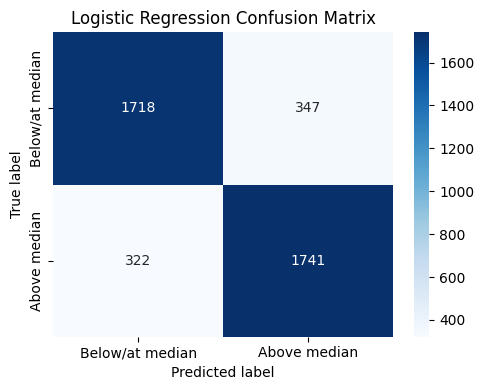

In [7]:
classification_target = (y > y.median()).astype(int)
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, classification_target, test_size=0.20, random_state=RANDOM_STATE,
    stratify=classification_target
)
classification_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
classification_model.fit(X_train_c, y_train_c)
y_class_pred = classification_model.predict(X_test_c)

accuracy = accuracy_score(y_test_c, y_class_pred)
precision = precision_score(y_test_c, y_class_pred, zero_division=0)
recall = recall_score(y_test_c, y_class_pred, zero_division=0)
cm = confusion_matrix(y_test_c, y_class_pred)
classification_metrics = {'Accuracy': float(accuracy), 'Precision': float(precision), 'Recall': float(recall), 'Confusion_Matrix': cm.tolist()}
print(json.dumps(classification_metrics, indent=2))
print('\nClassification report:')
print(classification_report(y_test_c, y_class_pred, zero_division=0))

plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Below/at median', 'Above median'], yticklabels=['Below/at median', 'Above median'])
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.title('Logistic Regression Confusion Matrix')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

## 7. Clustering — K-Means
Clustering is unsupervised, so the target label is not used. For manageable runtime and interpretation, use standardized numeric geographic and housing features. The elbow method and silhouette scores help guide the choice of K.

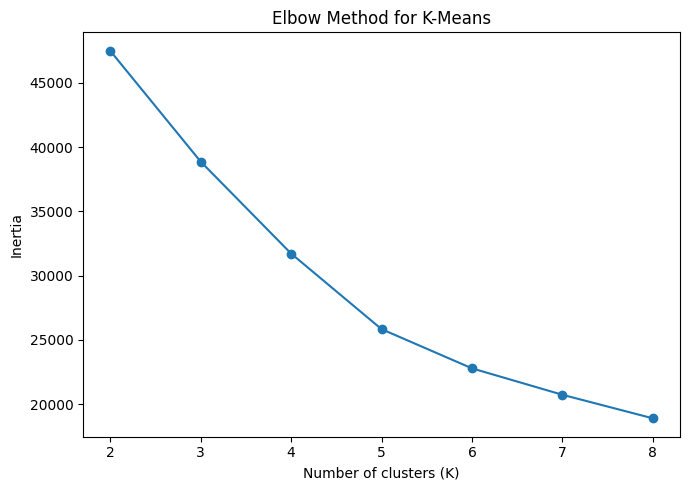

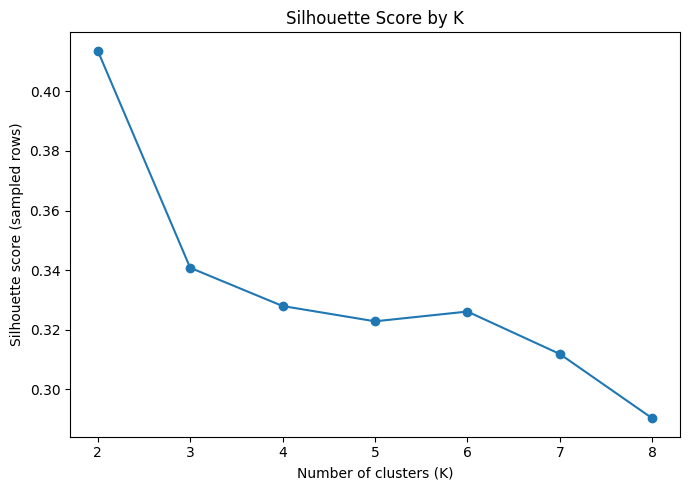

Selected K (highest sampled silhouette among K=2..8): 2
Sampled silhouette score: 0.4137


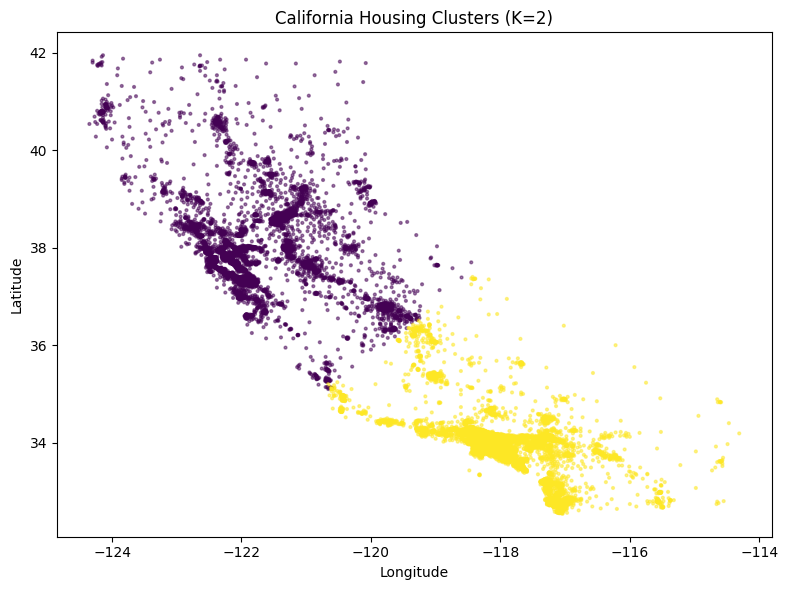

In [8]:
cluster_features = [c for c in ['longitude', 'latitude', 'housing_median_age', 'median_income'] if c in df.columns]
cluster_data = df[cluster_features].copy()
cluster_data = cluster_data.fillna(cluster_data.median(numeric_only=True))
cluster_scaled = StandardScaler().fit_transform(cluster_data)

k_values = range(2, 9)
inertias, silhouettes = [], []
# Evaluate silhouette on a fixed random sample to keep runtime reasonable.
rng = np.random.default_rng(RANDOM_STATE)
sample_size = min(3000, len(cluster_scaled))
sample_idx = rng.choice(len(cluster_scaled), size=sample_size, replace=False)
for k in k_values:
    km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels = km.fit_predict(cluster_scaled)
    inertias.append(float(km.inertia_))
    silhouettes.append(float(silhouette_score(cluster_scaled[sample_idx], labels[sample_idx])))

fig, ax1 = plt.subplots(figsize=(7, 5))
ax1.plot(list(k_values), inertias, marker='o')
ax1.set_xlabel('Number of clusters (K)')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method for K-Means')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'elbow_method.png', dpi=150)
plt.show()

plt.figure(figsize=(7, 5))
plt.plot(list(k_values), silhouettes, marker='o')
plt.xlabel('Number of clusters (K)')
plt.ylabel('Silhouette score (sampled rows)')
plt.title('Silhouette Score by K')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'silhouette_by_k.png', dpi=150)
plt.show()

best_k = list(k_values)[int(np.argmax(silhouettes))]
final_kmeans = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10)
cluster_labels = final_kmeans.fit_predict(cluster_scaled)
final_silhouette = float(silhouette_score(cluster_scaled[sample_idx], cluster_labels[sample_idx]))
print('Selected K (highest sampled silhouette among K=2..8):', best_k)
print('Sampled silhouette score:', round(final_silhouette, 4))

cluster_plot = df.copy()
cluster_plot['cluster'] = cluster_labels
plt.figure(figsize=(8, 6))
plt.scatter(cluster_plot['longitude'], cluster_plot['latitude'], c=cluster_plot['cluster'], cmap='viridis', s=4, alpha=0.5)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title(f'California Housing Clusters (K={best_k})')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'clusters_geography.png', dpi=150)
plt.show()
cluster_plot.groupby('cluster')[cluster_features + [target]].mean().to_csv(OUTPUT_DIR / 'cluster_summary.csv')

## 8. Save metrics and cleaned data
The files saved in `results/` can be included in the GitHub repository and referenced in the report.

In [9]:
all_metrics = {
    'dataset': {'rows': int(df.shape[0]), 'columns': int(df.shape[1]), 'features_for_regression': X.shape[1]},
    'regression_linear_regression': regression_metrics,
    'classification_logistic_regression': classification_metrics,
    'clustering_kmeans': {
        'selected_k': int(best_k),
        'silhouette_score_sampled': final_silhouette,
        'k_values': list(k_values),
        'inertia': inertias,
        'silhouette_scores_sampled': silhouettes,
        'features': cluster_features
    }
}
with open(OUTPUT_DIR / 'metrics.json', 'w', encoding='utf-8') as f:
    json.dump(all_metrics, f, indent=2)
df.to_csv(OUTPUT_DIR / 'housing_clean.csv', index=False)
print('Saved outputs:')
for p in sorted(OUTPUT_DIR.iterdir()):
    print('-', p)
print('\nFinal metrics summary:')
print(json.dumps(all_metrics, indent=2))

Saved outputs:
- results/cluster_summary.csv
- results/clusters_geography.png
- results/confusion_matrix.png
- results/correlation_matrix.png
- results/elbow_method.png
- results/housing_clean.csv
- results/metrics.json
- results/missing_values.csv
- results/regression_actual_vs_predicted.png
- results/silhouette_by_k.png
- results/target_distribution.png

Final metrics summary:
{
  "dataset": {
    "rows": 20640,
    "columns": 10,
    "features_for_regression": 9
  },
  "regression_linear_regression": {
    "MSE": 4908290571.346432,
    "RMSE": 70059.19333925014,
    "R2": 0.6254382675296266
  },
  "classification_logistic_regression": {
    "Accuracy": 0.8379360465116279,
    "Precision": 0.8338122605363985,
    "Recall": 0.8439166262724188,
    "Confusion_Matrix": [
      [
        1718,
        347
      ],
      [
        322,
        1741
      ]
    ]
  },
  "clustering_kmeans": {
    "selected_k": 2,
    "silhouette_score_sampled": 0.4136996978685438,
    "k_values": [
      2